In [1]:
import torch
import numpy as np
import random
import argparse
import cv2
import math
import torch.nn.functional as F
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "7"

from matplotlib import pyplot as plt
from torch.utils.data import DataLoader
from scipy.signal import welch, butter, lfilter

from archs.code_rppgnet import CodeRppgNet
from archs.physnet_divided import VideoFeatureExtractor, RppgEstimator, WeightMapGenerator, PPGFeatureExtractor
from datasets.rppg_datasets import VIPL, UBFC, PURE, COHFACE
from losses.CELoss import TorchLossComputer
from utils.utils import pearson_correlation_coefficient
from tqdm.autonotebook import tqdm

def cal_hr(output, Fs):

    def compute_complex_absolute_given_k(output, k, N):
        two_pi_n_over_N = 2 * math.pi * torch.arange(0, N, dtype=torch.float) / N
        hanning = torch.from_numpy(np.hanning(N)).type(torch.FloatTensor).view(1, -1)

        k = k.type(torch.FloatTensor)
        two_pi_n_over_N = two_pi_n_over_N
        hanning = hanning
            
        output = output.view(1, -1) * hanning
        output = output.view(1, 1, -1).type(torch.FloatTensor)
        k = k.view(1, -1, 1)
        two_pi_n_over_N = two_pi_n_over_N.view(1, 1, -1)
        complex_absolute = torch.sum(output * torch.sin(k * two_pi_n_over_N), dim=-1) ** 2 \
                           + torch.sum(output * torch.cos(k * two_pi_n_over_N), dim=-1) ** 2
        return complex_absolute
    
    output = output.view(1, -1)

    N = output.size()[1]
    bpm_range = torch.arange(40, 180, dtype=torch.float)
    unit_per_hz = Fs / N
    feasible_bpm = bpm_range / 60.0
    k = feasible_bpm / unit_per_hz
    
    # only calculate feasible PSD range [0.7,4]Hz
    complex_absolute = compute_complex_absolute_given_k(output, k, N)
    complex_absolute = (1.0 / complex_absolute.sum()) * complex_absolute
    whole_max_val, whole_max_idx = complex_absolute.view(-1).max(0) # max返回（values, indices）
    whole_max_idx = whole_max_idx.type(torch.float) # 功率谱密度的峰值对应频率即为心率

    return whole_max_idx + 40	# Analogous Softmax operator


def set_seed(seed=92):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def _init_fn(seed=92):
    np.random.seed(seed)

set_seed()

frame_rate = 30
bpm_range = torch.arange(40, 180, dtype=torch.float)

In [2]:
parser = argparse.ArgumentParser()
## general parameters
parser.add_argument('--num_rppg', type=int, default=160, help='the number of rPPG')
parser.add_argument('--drop_rate', type=int, default=0.2, help='the drop rate of CodeResNet')
parser.add_argument('--train_stage', type=str, default='train_codephys', help='train_stage = [train_codebook, train_codephys]')
parser.add_argument('--dataset', type=str, default='VIPL')
### add for codephys
parser.add_argument('--batch_size', type=int, default=4)
parser.add_argument('--lr', type=float, default=1e-4)
parser.add_argument('--gamma', type=float, default=0.5)
parser.add_argument('--weight_decay', type=float, default=5e-5)
parser.add_argument('--step_size', type=int, default=50)
parser.add_argument('--eval_step', type=int, default=1)
parser.add_argument('--epochs', type=int, default=200)
parser.add_argument('--echo_batches', type=int, default=500, help='the number of mini-batches to print the loss')
parser.add_argument('--save_path', type=str, default='', help='the path to save the model [ckpt, code, visulization]')

## encoder parameters
parser.add_argument('--enc_hidden_dim', type=int, default=512)
parser.add_argument('--enc_hidden_inner_dim', type=int, default=512)
parser.add_argument('--enc_num_layers', type=int, default=4)
parser.add_argument('--enc_dropout_ratio', type=float, default=0.0)

## decoder parameters
parser.add_argument('--dec_hidden_dim', type=int, default=32)
parser.add_argument('--dec_hidden_inner_dim', type=int, default=64)
parser.add_argument('--dec_num_layers', type=int, default=1)
parser.add_argument('--dec_dropout_ratio', type=float, default=0.0)

## adapter parameters
parser.add_argument('--ada_hidden_dim', type=int, default=64)
parser.add_argument('--ada_hidden_inner_dim', type=int, default=128)
parser.add_argument('--ada_num_layers', type=int, default=2)
parser.add_argument('--ada_dropout_ratio', type=float, default=0.0)

## codebook parameters
parser.add_argument('--vq_token_dim', type=int, default=64)
parser.add_argument('--token_class_num', type=int, default=64)
parser.add_argument('--fmix_rate', type=float, default=1.0, help='fmix rate should be 0 when training codebook')
parser.add_argument('--codebook_model_path', type=str, default="", help='the path to load the codebook model')


args = parser.parse_args([])

In [3]:
val_video_feature_extractor = VideoFeatureExtractor().cuda().eval()
val_rppg_estimator = RppgEstimator(frames=args.num_rppg).cuda().eval()
val_codebook_module = CodeRppgNet(args).cuda().eval()
val_weight_map_generator = WeightMapGenerator().cuda().eval()
ckpt_dir = '/data2/chushuyang/CodePhys_proj/0811_1210/ckpt'
epoch_load = 7
val_video_feature_extractor.load_state_dict(torch.load(f'{ckpt_dir}/video_feature_extractor_{epoch_load}.pth', map_location=torch.device('cuda:0')))
val_rppg_estimator.load_state_dict(torch.load(f'{ckpt_dir}/rppg_estimator_{epoch_load}.pth', map_location=torch.device('cuda:0')))
val_codebook_module.load_state_dict(torch.load(f'{ckpt_dir}/codebook_{epoch_load}.pth', map_location=torch.device('cuda:0')))
val_weight_map_generator.load_state_dict(torch.load(f'{ckpt_dir}/weight_map_generator_{epoch_load}.pth', map_location=torch.device('cuda:0')))

<All keys matched successfully>

In [10]:
from thop import profile
val_PPGFeatureExtractor = PPGFeatureExtractor(args).cuda().eval()
macs, params = profile(val_PPGFeatureExtractor, inputs=(torch.randn(1, 160).cuda(), ))
print(f'for PPGFeatureExtractor, flops: {macs / 1e9} GFlops, params: {params / 1e6} M')
input_sample = torch.randn(1, 3, 160, 128, 128).cuda()
macs, params = profile(val_video_feature_extractor, inputs=(input_sample, ))
print(f'for video_feature_extractor, flops: {macs / 1e9} GFlops, params: {params / 1e6} M')
video_feature_sample = val_video_feature_extractor(input_sample)
macs, params = profile(val_weight_map_generator, inputs=(video_feature_sample, ))
print(f'for weight_map_generator, flops: {macs / 1e9} GFlops, params: {params / 1e6} M')
spatial_weight_map_sample = val_weight_map_generator(video_feature_sample)
mask_video_feature = video_feature_sample * spatial_weight_map_sample.unsqueeze(1).unsqueeze(1)
macs, params = profile(val_rppg_estimator, inputs=(mask_video_feature, ))
print(f'for rppg_estimator, flops: {macs / 1e9} GFlops, params: {params / 1e6} M')
print(mask_video_feature.shape)
rPPG_peak = val_rppg_estimator(mask_video_feature)  
rPPG = (rPPG_peak - rPPG_peak.mean(dim=-1, keepdim=True)) / \
        torch.abs(rPPG_peak).max(dim=-1, keepdim=True).values  # normalize
print(rPPG.shape, mask_video_feature.shape)
rPPG, _, _ = val_codebook_module(rPPG, mask_video_feature)
macs, params = profile(val_codebook_module, inputs=(rPPG, mask_video_feature))
print(f'for codebook_module, flops: {macs / 1e9} GFlops, params: {params / 1e6} M')

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv1d'>.
[WARN] Cannot find rule for <class 'torch.nn.modules.normalization.LayerNorm'>. Treat it as zero Macs and zero Params.
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.ConvTranspose1d'>.
[WARN] Cannot find rule for <class 'archs.code_rppgnet.EmbedLayer'>. Treat it as zero Macs and zero Params.
[WARN] Cannot find rule for <class 'torch.nn.modules.container.ModuleList'>. Treat it as zero Macs and zero Params.
[WARN] Cannot find rule for <class 'archs.physnet_divided.PPGFeatureExtractor'>. Treat it as zero Macs and zero Params.
for PPGFeatureExtractor, flops: 5.38985472 GFlops, params: 4.297792 M
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv3d'>.
[INFO] Register count_bn() for <class 'torch.nn.modules.batchnorm.BatchNorm3d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[WARN] Cannot find rule for <class 'torch.nn.modules.container.Sequential'>. 

/home/chushuyang/miniconda3/envs/rppg/lib/python3.8/site-packages/thop/vision/basic_hooks.py:92: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  kernel = torch.DoubleTensor([*(x[0].shape[2:])]) // torch.DoubleTensor(list((m.output_size,))).squeeze()


In [4]:
# dataloader_test = DataLoader(PURE(data_dir='/data/chushuyang/pure', T=-1, train='test', w=128, h=128), batch_size=1, shuffle=False, num_workers=0, worker_init_fn=_init_fn)
dataloader_test = DataLoader(VIPL(data_dir='/data2/chushuyang/VIPL', T=-1, train='test', w=128, h=128, fold=1), batch_size=1, shuffle=False, num_workers=0, worker_init_fn=_init_fn)
# dataloader_test = DataLoader(UBFC(data_dir='/data/chushuyang/UBFC_RAW', T=-1, train='test', w=128, h=128), batch_size=1, shuffle=False, num_workers=0, worker_init_fn=_init_fn)
print(next(iter(dataloader_test))['ecg'].shape)

torch.Size([1, 1009])


In [5]:
import copy
hr_gt = []
hr_codephys = []
bpm_range = torch.arange(40, 180, dtype=torch.float).cuda()

with torch.no_grad():

    for i, sample_batched in enumerate(tqdm(dataloader_test)):
        # get the inputs
        inputs, ecg = sample_batched['video'].cuda(), sample_batched['ecg'].cuda()
        clip_average_HR = sample_batched['clip_avg_hr'].cuda()

        num_clip = 3
        input_len = inputs.shape[2]
        input_len = input_len - input_len % (num_clip * 4)
        clip_len = input_len // num_clip
        inputs = inputs[:, :, :input_len, :, :]
        ecg = ecg[:, :input_len]

        new_args = copy.deepcopy(args)
        new_args.num_rppg = clip_len
        val_rppg_estimator = RppgEstimator(frames=new_args.num_rppg).cuda()
        val_rppg_estimator.load_state_dict(torch.load(f'{ckpt_dir}/rppg_estimator_{epoch_load}.pth', map_location=torch.device('cuda:0')))
        val_rppg_estimator.eval()
        val_codebook_module = CodeRppgNet(new_args).cuda()
        val_codebook_module.load_state_dict(torch.load(f'{ckpt_dir}/codebook_{epoch_load}.pth', map_location=torch.device('cuda:0')))
        val_codebook_module.eval()

        psd_gt_total = 0
        psd_codephys_total = 0
        for idx in range(num_clip):

            inputs_iter = inputs[:, :, idx*clip_len : (idx+1)*clip_len, :, :]
            ecg_iter = ecg[:, idx*clip_len : (idx+1)*clip_len]

            psd_gt = TorchLossComputer.complex_absolute(ecg_iter, 30, bpm_range)
            psd_gt_total += psd_gt.view(-1).max(0)[1].cpu() + 40

            video_feature = val_video_feature_extractor(inputs_iter)

            spatial_weight_map = val_weight_map_generator(video_feature)
            mask_video_feature = video_feature * spatial_weight_map.unsqueeze(1).unsqueeze(1)
            rPPG_peak = val_rppg_estimator(mask_video_feature)
            rPPG = (rPPG_peak - rPPG_peak.mean(dim=-1, keepdim=True)) / \
                    torch.abs(rPPG_peak).max(dim=-1, keepdim=True).values  # normalize
            rPPG, _, _ = val_codebook_module(rPPG, mask_video_feature)
            
            psd_codephys = TorchLossComputer.complex_absolute(rPPG[0], 30, bpm_range)
            psd_codephys_total += psd_codephys.view(-1).max(0)[1].cpu() + 40
            
        hr_codephys.append(psd_codephys_total / num_clip)
        hr_gt.append(psd_gt_total / num_clip)

print(f'mae: {np.mean(np.abs(np.array(hr_gt) - np.array(hr_codephys)))}')
print(f'rmse: {np.sqrt(np.mean(np.square(np.array(hr_gt) - np.array(hr_codephys))))}')

  0%|          | 0/471 [00:00<?, ?it/s]

mae: 4.298655033111572
rmse: 7.293787479400635


KstestResult(statistic=0.10851576551027031, pvalue=2.7644772235804513e-05)
KstestResult(statistic=0.12963605788787486, pvalue=2.3197885510013408e-07)


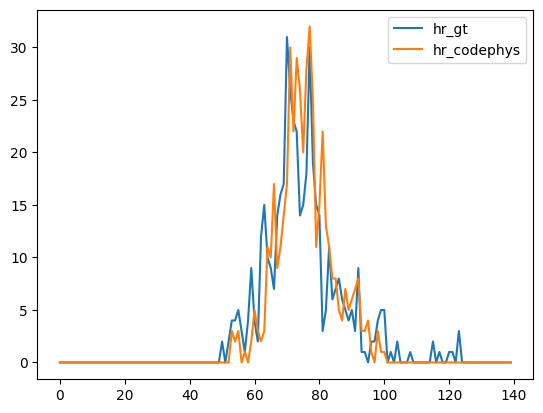

In [19]:
hr_codephys_conut = np.zeros(140)
hr_gt_conut = np.zeros(140)

mean_of_gt = np.mean(hr_gt)
sd_of_gt = np.std(hr_gt)

for i in range(len(hr_gt)):
    hr_codephys_conut[int(hr_codephys[i])] += 1
    hr_gt_conut[int(hr_gt[i])] += 1
    
plt.plot(hr_gt_conut, label='hr_gt')
plt.plot(hr_codephys_conut, label='hr_codephys')
plt.legend()

# cal the prob of gt/codephys can be sampled from norm_distribution by KS test
from scipy.stats import kstest
print(kstest(hr_gt, 'norm', (mean_of_gt, sd_of_gt)))
print(kstest(hr_codephys, 'norm', (mean_of_gt, sd_of_gt)))


统计量： 0.5646538633400996
p值： 0.5723218874576715


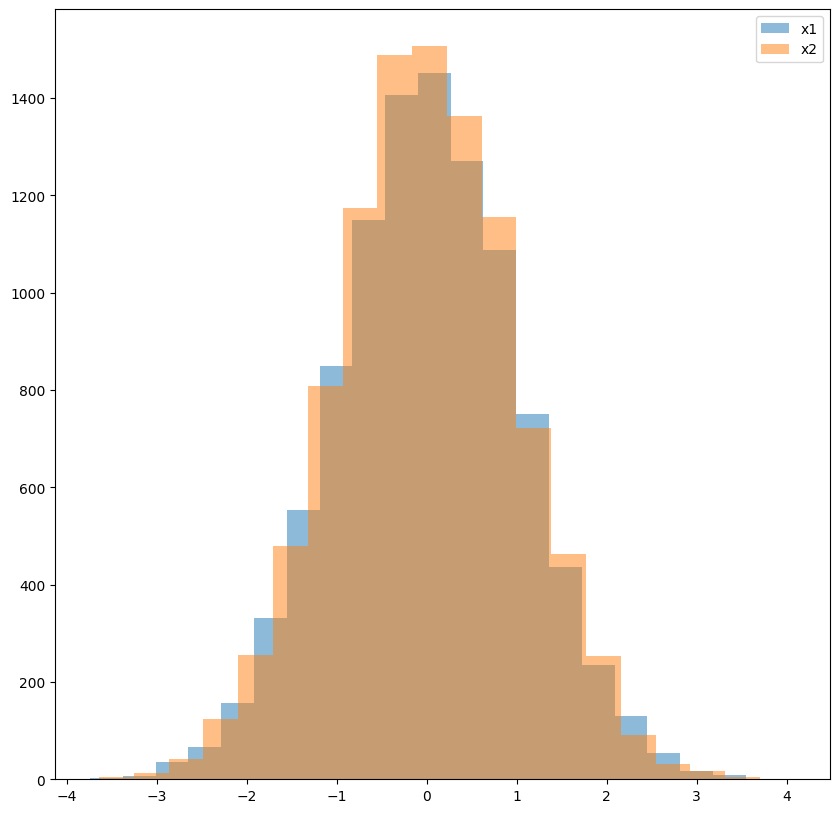

In [57]:
import numpy as np
from scipy import stats

# 假设这是你的样本数据
x1 = np.random.normal(0, 1, 10000)
# x2 = x1 + 0.0000000000000001
x2 = np.random.normal(0, 1, 10000)

# 进行配对Wilcoxon检验
stat, p_value = stats.ttest_rel(x1, x2)

print("统计量：", stat)
print("p值：", p_value)

# draw the distribution of x1 and x2
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
plt.hist(x1, bins=20, alpha=0.5, label='x1')
plt.hist(x2, bins=20, alpha=0.5, label='x2')
plt.legend()
plt.show()

In [6]:
import copy
hr_gt = []
hr_codephys = []
bpm_range = torch.arange(40, 180, dtype=torch.float).cuda()

class RppgClass():
    def __init__(self) -> None:
        self.num = 0
        self.sum = 0
        self.value = 0

    def update(self, value):
        self.num += 1
        self.sum += value
        self.value = self.sum / self.num

class_mae_list = [RppgClass() for _ in range(140)]

with torch.no_grad():

    for i, sample_batched in enumerate(tqdm(dataloader_test)):
        # get the inputs
        inputs, ecg = sample_batched['video'].cuda(), sample_batched['ecg'].cuda()
        clip_average_HR = sample_batched['clip_avg_hr'].cuda()

        num_clip = 3
        input_len = inputs.shape[2]
        input_len = input_len - input_len % (num_clip * 4)
        clip_len = input_len // num_clip
        inputs = inputs[:, :, :input_len, :, :]
        ecg = ecg[:, :input_len]

        new_args = copy.deepcopy(args)
        new_args.num_rppg = clip_len
        val_rppg_estimator = RppgEstimator(frames=new_args.num_rppg).cuda()
        val_rppg_estimator.load_state_dict(torch.load(f'{ckpt_dir}/rppg_estimator_{epoch_load}.pth', map_location=torch.device('cuda:0')))
        val_rppg_estimator.eval()
        val_codebook_module = CodeRppgNet(new_args).cuda()
        val_codebook_module.load_state_dict(torch.load(f'{ckpt_dir}/codebook_{epoch_load}.pth', map_location=torch.device('cuda:0')))
        val_codebook_module.eval()

        psd_gt_total = 0
        psd_codephys_total = 0
        for idx in range(num_clip):

            inputs_iter = inputs[:, :, idx*clip_len : (idx+1)*clip_len, :, :]
            ecg_iter = ecg[:, idx*clip_len : (idx+1)*clip_len]

            psd_gt = TorchLossComputer.complex_absolute(ecg_iter, 30, bpm_range)
            psd_gt_total += psd_gt.view(-1).max(0)[1].cpu() + 40

            video_feature = val_video_feature_extractor(inputs_iter)
            spatial_weight_map = val_weight_map_generator(video_feature)
            mask_video_feature = video_feature * spatial_weight_map.unsqueeze(1).unsqueeze(1)
            rPPG_peak = val_rppg_estimator(mask_video_feature)
            rPPG = (rPPG_peak - rPPG_peak.mean(dim=-1, keepdim=True)) / \
                    torch.abs(rPPG_peak).max(dim=-1, keepdim=True).values  # normalize
            rPPG, _, _ = val_codebook_module(rPPG, mask_video_feature)
            
            psd_codephys = TorchLossComputer.complex_absolute(rPPG[0], 30, bpm_range)
            psd_codephys_total += psd_codephys.view(-1).max(0)[1].cpu() + 40
        
        gt_index = psd_gt_total // num_clip
        # print(gt_index)
        class_mae_list[gt_index].update(np.abs(psd_codephys_total / num_clip - psd_gt_total / num_clip))
        # print(class_mae_list[gt_index].value)
        hr_codephys.append(psd_codephys_total / num_clip)
        hr_gt.append(psd_gt_total / num_clip)

print(f'mae: {np.mean(np.abs(np.array(hr_gt) - np.array(hr_codephys)))}')
print(f'rmse: {np.sqrt(np.mean(np.square(np.array(hr_gt) - np.array(hr_codephys))))}')

  0%|          | 0/471 [00:00<?, ?it/s]

/tmp/ipykernel_3319709/2599510142.py:63: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  gt_index = psd_gt_total // num_clip


mae: 4.298655033111572
rmse: 7.293787479400635


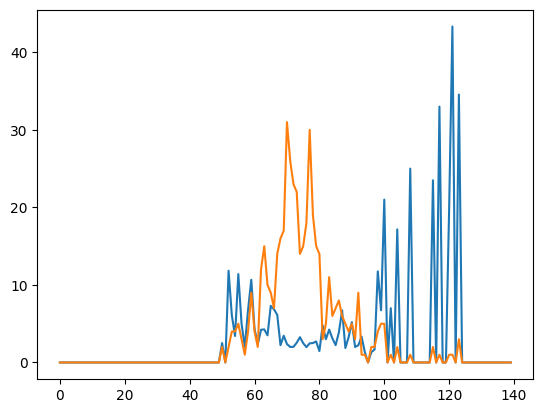

In [7]:
value_list = [class_mae_list[i].value for i in range(140)]
num_list = [class_mae_list[i].num for i in range(140)]
plt.plot(value_list)
plt.plot(num_list)
plt.show()

In [11]:
#### 使用普通的方法测试 codephys-v3 clip-level
hr_gt_list = []
hr_physnet_list = []
hr_codebook_list = []
frame_path_list = []
bpm_range = torch.arange(40, 180, dtype=torch.float).cuda()

with torch.no_grad():

    for i, sample_batched in enumerate(tqdm(dataloader_test)):
        inputs, ecg = sample_batched['video'].cuda(), sample_batched['ecg'].cuda()
        clip_average_HR = sample_batched['clip_avg_hr'].cuda()
        frame_rate = 30
        

        hr_gt_list.append(clip_average_HR[0].item())
        
        ## for physnet divieded:
        video_feature = val_video_feature_extractor(inputs)
        spatial_weight_map = val_weight_map_generator(video_feature)
        mask_video_feature = video_feature * spatial_weight_map.unsqueeze(1).unsqueeze(1)
        rPPG_peak = val_rppg_estimator(mask_video_feature)
        rPPG = (rPPG_peak - rPPG_peak.mean(dim=-1, keepdim=True)) / \
                torch.abs(rPPG_peak).max(dim=-1, keepdim=True).values  # normalize

        psd = TorchLossComputer.complex_absolute(rPPG_peak[0], frame_rate, bpm_range)
        hr_physnet_list.append(psd.view(-1).max(0)[1].cpu() + 40)

        # ## for codebook:
        rPPG, _, _ = val_codebook_module(rPPG, mask_video_feature)

        psd_vq = TorchLossComputer.complex_absolute(rPPG[0], frame_rate, bpm_range) 
        hr_codebook_list.append(psd_vq.view(-1).max(0)[1].cpu() + 40)


print(f'mae of physnet: {np.mean(np.abs(np.array(hr_gt_list) - np.array(hr_physnet_list)))}')
print(f'rmse of physnet: {np.sqrt(np.mean(np.square(np.array(hr_gt_list) - np.array(hr_physnet_list))))}')
print(f'mae of codebook: {np.mean(np.abs(np.array(hr_gt_list) - np.array(hr_codebook_list)))}')
print(f'rmse of codebook: {np.sqrt(np.mean(np.square(np.array(hr_gt_list) - np.array(hr_codebook_list))))}')

  0%|          | 0/836 [00:00<?, ?it/s]

mae of physnet: 24.413875598086126
rmse of physnet: 29.252448472338077
mae of codebook: 6.832535885167464
rmse of codebook: 10.013985435690431


In [4]:
x = eval('["np_loss", "ce_loss"]')
print(x)
y = eval('[1, 2]')
print(y)
print(dict(zip(x, y)))

['np_loss', 'ce_loss']
[1, 2]
{'np_loss': 1, 'ce_loss': 2}
